In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

In [45]:
from pathlib import Path

import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler


from notebooks.imports import *
from src.utils import pmf_utils

### Config

In [3]:
from config import dir_config

raw_dir = Path(dir_config.data.raw)
processed_dir = Path(dir_config.data.processed)

### Utils functions

### Load Data

In [99]:
data = pd.read_csv(Path(processed_dir, "valid_data.csv"), index_col=None)
data["pulse_onset"] = pd.to_numeric(data["pulse_onset"], errors="coerce")
data.head()

,idx_session,data_source,subject_id,session_id,idx_valid_trial,idx_correction,is_correction_trial,signed_coherence,target,choice,reaction_time,outcome,reward_amount,fixation_duration,stimulus_duration,reinforcement_duration,intertrial_delay,is_pulse_trial,pulse_onset,pulse_duration,pulse_coherence,pulse_type
0,0,uw,DBM11,10_1,1,0,False,100,1,1,1.080817,1.0,1.5,0.530901,25.0,0.0,0.500000,True,0.41675,0.06668,-100,-3.0
1,0,uw,DBM11,10_1,2,0,False,100,1,0,0.469520,0.0,NaN,0.577326,25.0,0.0,13.689771,False,0.41675,0.06668,100,0.0
2,0,uw,DBM11,10_1,3,0,False,-100,-1,0,2.171707,1.0,1.5,0.556890,25.0,0.0,0.500000,True,0.41675,0.06668,100,3.0
3,0,uw,DBM11,10_1,4,0,False,-100,-1,0,0.476003,1.0,1.5,0.548262,25.0,0.0,0.500000,False,0.05001,0.06668,-100,-0.0
4,0,uw,DBM11,10_1,5,0,False,-100,-1,0,0.971870,1.0,1.5,0.561377,25.0,0.0,0.500000,False,0.23338,0.06668,-100,-0.0


In [100]:
data.pulse_onset[~np.isnan(data.pulse_onset)].sum()

np.float64(23336.260705382843)

(array([2.1682e+04, 5.6360e+03, 1.5100e+02, 0.0000e+00, 2.4600e+02,
        3.1335e+04, 1.4380e+03, 4.0000e+00, 0.0000e+00, 3.3875e+04]),
 array([0.00999331, 0.05066898, 0.09134465, 0.13202032, 0.17269599,
        0.21337166, 0.25404733, 0.29472299, 0.33539866, 0.37607433,
        0.41675   ]),
 <BarContainer object of 10 artists>)

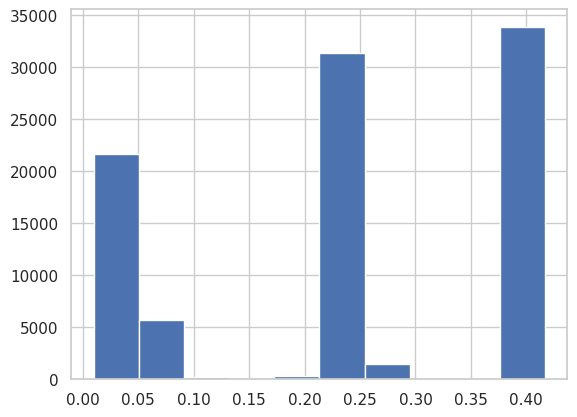

In [5]:
plt.hist(data.pulse_onset)

In [ ]:
import numpy as np
import pandas as pd  # Assuming data is a pandas DataFrame




## MARY'S APPROACH

In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler


# Logistic sigmoid function (activation function)
def expoit_func(x):
	return 1 / (1 + np.exp(-x))


# Loss function (Mean Squared Error after logistic activation)
def loss(y_true, X, w, bias):
	# Prediction using logistic regression with NaN handling
	y_pred = np.array([np.dot(X[trial_num][~np.isnan(X[trial_num])], w[~np.isnan(X[trial_num])]) for trial_num in range(X.shape[0])]) + bias
	y_pred = expoit_func(y_pred)  # Sigmoid activation
	return np.mean((y_true - y_pred) ** 2)


# Gradient of the loss function with respect to weights and bias
def gradients(y_true, X, w, bias):
	# Initialize gradients
	dw = np.zeros_like(w)
	db = 0

	# Compute predictions and errors
	y_pred = np.array([np.dot(X[trial_num][~np.isnan(X[trial_num])], w[~np.isnan(X[trial_num])]) for trial_num in range(X.shape[0])]) + bias
	y_pred = expoit_func(y_pred)

	# Calculate the error
	error = y_pred - y_true

	# Compute gradients for weights and bias
	for trial_num in range(X.shape[0]):
		valid_indices = ~np.isnan(X[trial_num])
		dw[valid_indices] += error[trial_num] * X[trial_num][valid_indices]

	db = np.sum(error)

	# Average gradients (for batch processing)
	dw /= X.shape[0]
	db /= X.shape[0]

	return dw, db


# Gradient Descent Optimization
def fit_logistic_regression(X, y, timesteps, learning_rate=0.01, num_epochs=1000):
	# Initialize weights and bias
	w = np.random.randn(X.shape[1])
	bias = 0

	# Iterate through epochs and update weights using gradient descent
	for epoch in range(num_epochs):
		dw, db = gradients(y, X, w, bias)

		# Update weights and bias
		w -= learning_rate * dw
		bias -= learning_rate * db

		# Print loss at every 100th epoch (for tracking progress)
		if epoch % 100 == 0:
			current_loss = loss(y, X, w, bias)
			print(f"Epoch {epoch}, Loss: {current_loss}")

	return w, bias


# Example data (replace with actual data)
timesteps = 600
t_weights = np.random.random(timesteps).reshape(-1, 1)

# StandardScaler to scale the input data
scaler = StandardScaler()
x_coh = scaler.fit_transform(coh_timeseries.T).T  # Assuming coh_timeseries is the input data matrix
y = data.choice.values  # Assuming 'data' contains the target variable

# Fit the logistic regression model
w, bias = fit_logistic_regression(x_coh, y, timesteps)

# Final weights and bias
print(f"Optimal weights: {w}")
print(f"Optimal bias: {bias}")


Training on device: cpu
Epoch 0, Loss: 0.2471277117729187
Epoch 100, Loss: 0.22673556208610535
Epoch 200, Loss: 0.22542652487754822
Epoch 300, Loss: 0.2251337170600891
Epoch 400, Loss: 0.22501049935817719
Epoch 500, Loss: 0.22493115067481995
Epoch 600, Loss: 0.2248685508966446
Epoch 700, Loss: 0.2248152643442154
Epoch 800, Loss: 0.22476856410503387
Epoch 900, Loss: 0.22472701966762543
Optimal bias: [0.00076767]


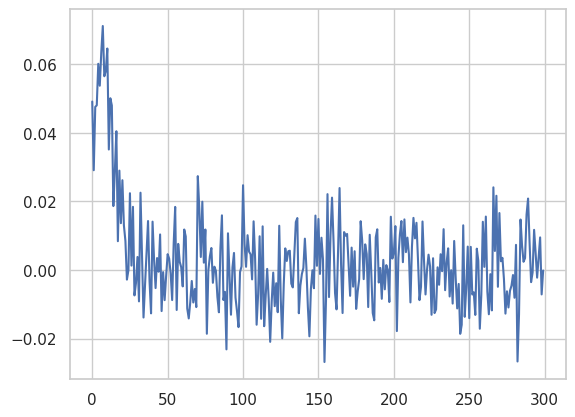

In [ ]:
import torch
import torch.nn as nn
import numpy as np
from sklearn.preprocessing import StandardScaler


# Logistic sigmoid function (activation function)
def expoit_func(x):
	return torch.sigmoid(x)  # Use PyTorch's built-in sigmoid for efficiency


# Loss function (Mean Squared Error after logistic activation)
def loss_fn(y_true, y_pred):
	return torch.mean((y_true - y_pred) ** 2)

# Model definition for logistic regression
class LogisticRegressionModel(nn.Module):
	def __init__(self, input_dim):
		super(LogisticRegressionModel, self).__init__()
		# Initialize weights with small values
		self.weights = nn.Parameter(torch.randn(input_dim) * 0.01)
		self.bias = nn.Parameter(torch.zeros(1))

	def forward(self, X):
		# Apply weight and bias and clip inputs to avoid extreme values
		# Create a mask for valid (non-NaN) values
		valid_mask = ~torch.isnan(X)  # Mask for non-NaN values

		# Zero-out NaN values to avoid affecting the dot product
		X_valid = torch.where(valid_mask, X, torch.zeros_like(X))  # Replace NaNs with zeros

		# Compute the weighted sum of valid features only
		linear_input = torch.matmul(X_valid, self.weights) + self.bias

		# Clip input to the sigmoid to avoid overflow
		linear_input = torch.clamp(linear_input, -10, 10)  # Clip inputs to a safe range

		return expoit_func(linear_input)

# Gradient Descent Optimization with PyTorch
def fit_logistic_regression(X, y, timesteps, learning_rate=0.01, num_epochs=1000, device="cpu"):
	# Convert to torch tensors and move to the specified device (CPU or GPU)
	X_tensor = torch.tensor(X, dtype=torch.float32).to(device)
	y_tensor = torch.tensor(y, dtype=torch.float32).to(device)

	# Initialize the model and move it to the device
	model = LogisticRegressionModel(X_tensor.shape[1]).to(device)

	# Define the optimizer (Stochastic Gradient Descent)
	optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

	# Training loop
	for epoch in range(num_epochs):
		model.train()  # Set the model to training mode

		# Forward pass
		y_pred = model(X_tensor)

		# Compute loss
		loss = loss_fn(y_tensor, y_pred)

		# Backward pass and optimization
		optimizer.zero_grad()  # Zero the gradients before backward pass
		loss.backward()  # Backpropagation
		optimizer.step()  # Update weights using the gradients

		# Print loss every 100 epochs
		if epoch % 100 == 0:
			print(f"Epoch {epoch}, Loss: {loss.item()}")

	return model.weights.detach().cpu().numpy(), model.bias.detach().cpu().numpy()


def get_coh_timeseries(coherence, pulse_onset, pulse_coherence, pulse_duration, reaction_time, freq=60, max_rt=10):
	# Initialize timeseries with NaN values
	coh_timeseries = np.full(freq * max_rt, np.nan)

	# Handle NaN values safely
	reaction_time = 0 if np.isnan(reaction_time) else int(reaction_time * 1000 / freq)
	coh_timeseries[reaction_time:] = coherence

	if not np.isnan(pulse_onset) and not np.isnan(pulse_duration):
		pulse_onset = int(pulse_onset * 1000 / freq)
		pulse_duration = int(pulse_duration * 1000 / freq)

		# Ensure we don't exceed index 600
		end_idx = min(pulse_onset + pulse_duration, freq * max_rt)ffsefse
		coh_timeseries[reaction_time - end_idx : reaction_time - ] = pulse_coherence

	return coh_timeseries


# Example data (replace with actual data)
max_rt = 5
freq = 60
timesteps = freq * max_rt
t_weights = np.random.random(timesteps).reshape(-1, 1)


temp_data = data[data.reaction_time < max_rt]

# Apply function to each row of DataFrame
coh_timeseries = temp_data.apply(lambda row: get_coh_timeseries(row.signed_coherence, row.pulse_onset, row.pulse_coherence, row.pulse_duration, row.reaction_time, freq=freq, max_rt=max_rt), axis=1)
coh_timeseries = np.array(list(coh_timeseries))

# StandardScaler to scale the input data
scaler = StandardScaler()
x_coh = scaler.fit_transform(coh_timeseries)  # Assuming coh_timeseries is the input data matrix
y = temp_data.choice.values  # Assuming 'data' contains the target variable

# Check for GPU availability and set the device
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Training on device: {device}")

# Fit the logistic regression model
w, bias = fit_logistic_regression(x_coh, y, timesteps, device=device)

# # Final weights and bias
print(f"Optimal bias: {bias}")
plt.plot(w)